# Loan Applications: Visualisation

**Author:** Maria Pupysheva · **Date:** November 2026

**Data:** the cleaned loan applications from notebook 03 (614 applications), saved as
`data/loans_clean.parquet`. Run notebook 03 first to create this file.

**Goal:** turn the findings of notebook 03 into clear charts, and build one headline chart that
tells the main story.

**Note:** `Loan_Status` records whether the loan was **approved**, not whether it was repaid.
The charts describe the lender's past decisions, not repayment risk.

**Tools:** Python 3.12 · pandas · Matplotlib · seaborn

**Contents**
1. Setup · 2. Income · 3. What drives approval · 4. Headline chart · 5. Summary

## 1. Setup
Load the libraries, the shared `approval_by` helper (`loan_helpers.py`) and the cleaned data
saved at the end of notebook 03.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

from loan_helpers import approval_by   # applications and approval rate per group

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
loans = pd.read_parquet("../data/loans_clean.parquet")
loans.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Loan_ID              614 non-null    str     
 1   Gender               614 non-null    str     
 2   Married              614 non-null    str     
 3   Dependents           614 non-null    Int64   
 4   Education            614 non-null    str     
 5   Self_Employed        614 non-null    str     
 6   ApplicantIncome      614 non-null    int64   
 7   CoapplicantIncome    614 non-null    float64 
 8   LoanAmount           614 non-null    float64 
 9   Loan_Amount_Term     614 non-null    float64 
 10  Credit_History       564 non-null    float64 
 11  Property_Area        614 non-null    str     
 12  Loan_Status          614 non-null    str     
 13  credit_history       614 non-null    str     
 14  total_income         614 non-null    float64 
 15  monthly_repayment    614 non-null 

## 2. Income

### Q1. Income distribution
How is total monthly income distributed, and what does a log scale show that a linear scale hides?

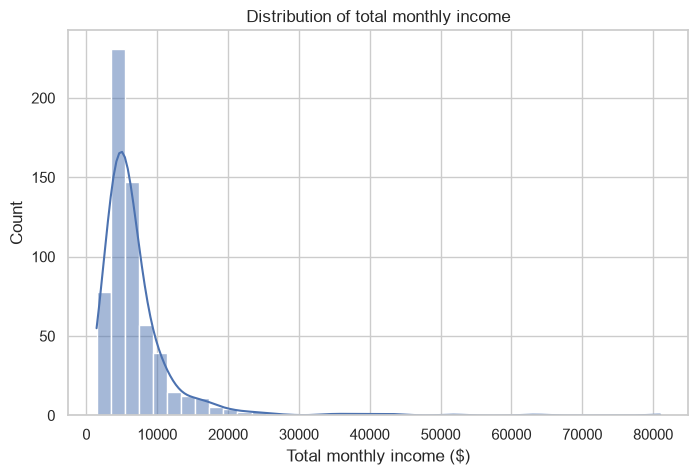

In [3]:
sns.histplot(data=loans, x="total_income", bins=40, kde=True)
plt.title("Distribution of total monthly income")
plt.xlabel("Total monthly income ($)")
plt.show()

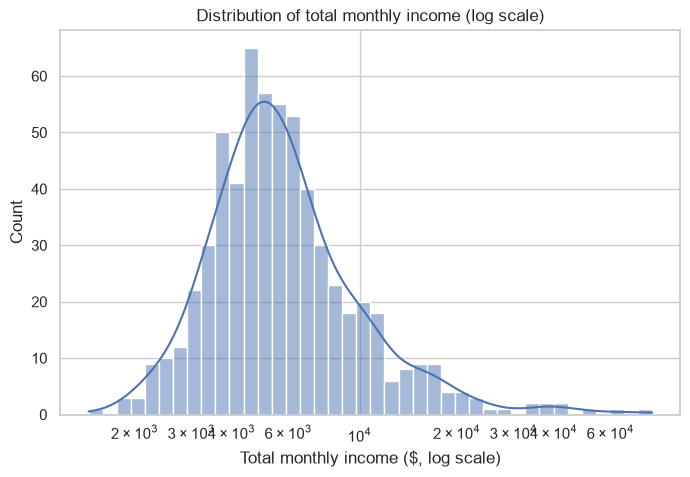

In [4]:
sns.histplot(data=loans, x="total_income", bins=40, kde=True, log_scale=True)
plt.title("Distribution of total monthly income (log scale)")
plt.xlabel("Total monthly income ($, log scale)")
plt.show()

**Observation:** Total monthly income is strongly right-skewed: most applicants earn between about \$3,000 and \$8,000 (median \$5,417), while a few earn up to \$80,000. On the linear scale this long tail squeezes the main group into a few bars. On the log scale the main group is roughly symmetric around \$5,000, and the high incomes remain visible as a separate tail.

### Q2. Income of approved and rejected applicants
Does typical income differ between approved and rejected applications?

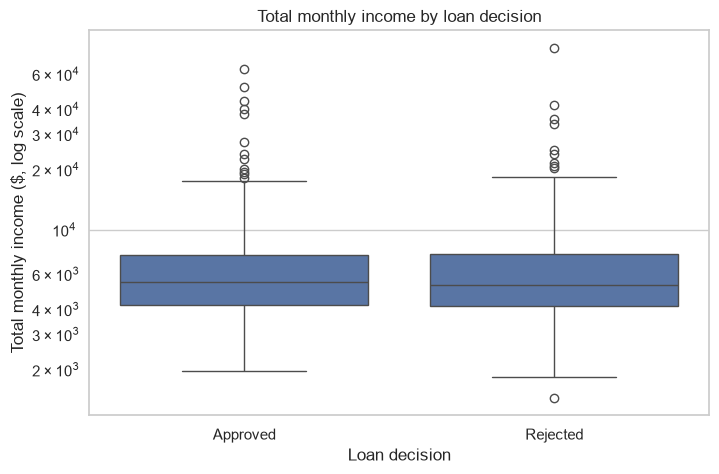

Loan_Status
N    5289.5
Y    5439.0
Name: total_income, dtype: float64

In [5]:
sns.boxplot(data=loans, x="Loan_Status", y="total_income", order=["Y", "N"], log_scale=True)
plt.title("Total monthly income by loan decision")
plt.xlabel("Loan decision")
plt.ylabel("Total monthly income ($, log scale)")
plt.xticks([0, 1], ["Approved", "Rejected"])
plt.show()

loans.groupby("Loan_Status")["total_income"].median()

**Observation:** Median monthly income is almost the same for rejected (\$5,290) and approved (\$5,439) applications, a difference of less than 3%. The boxes overlap almost completely, so income on its own barely separates the two groups. This matches notebook 03: credit history and affordability (repayment relative to income) are much stronger signals than income alone.

## 3. What drives approval

### Q3. Credit history
How does the approval rate differ between good, bad and missing credit history?

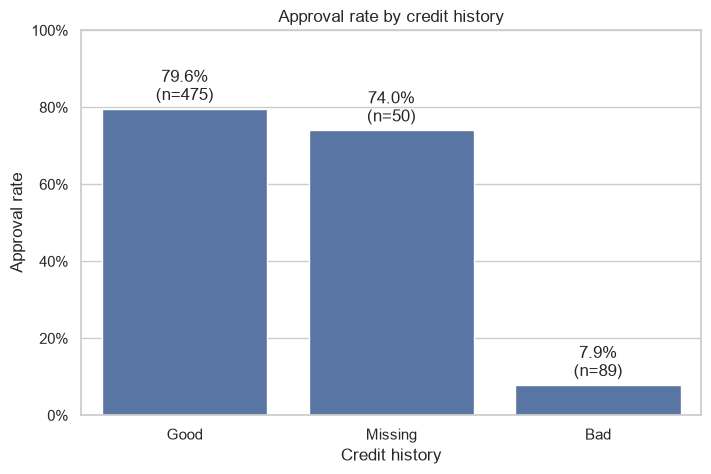

In [6]:
order = ["Good", "Missing", "Bad"]

# Approval rate per credit history group, in the same order as the bars
credit_hist_approval = approval_by(loans, "credit_history").loc[order].reset_index()

ax = sns.barplot(data=credit_hist_approval, x="credit_history", y="approval_rate", order=order)

# Labels: rate + number of applicants
labels = [
    f"{rate:.1%}\n(n={n})"
    for rate, n in zip(credit_hist_approval["approval_rate"], credit_hist_approval["applications"])
]
ax.bar_label(ax.containers[0], labels=labels, label_type="edge", padding=3)

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1)
plt.title("Approval rate by credit history")
plt.xlabel("Credit history")
plt.ylabel("Approval rate")
plt.show()

**Observation:** Credit history is the strongest signal in the data: applicants with a good history were approved at 79.6%, compared with 7.9% for a bad history, about 10 times lower. Applicants with a missing history (n=50) were approved at 74.0%. The group is smaller, so the exact rate is less certain, but it is clearly much closer to “Good” than to “Bad”: a missing history is not a warning sign.

### Q4. Affordability
How does the approval rate change across repayment-to-income bands?

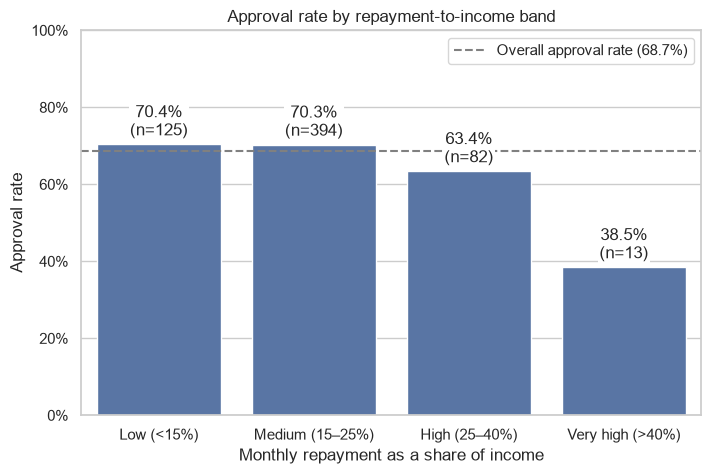

In [7]:
# Approval rate per affordability band (natural order Low → Very high is kept by the category)
afford_approval = approval_by(loans, "affordability").reset_index()
overall_rate = loans["approved"].mean()

ax = sns.barplot(data=afford_approval, x="affordability", y="approval_rate")

# Labels: rate + number of applicants
labels = [
    f"{rate:.1%}\n(n={n})"
    for rate, n in zip(afford_approval["approval_rate"], afford_approval["applications"])
]
ax.bar_label(ax.containers[0], labels=labels, label_type="edge", padding=3,
             bbox=dict(facecolor="white", edgecolor="none", pad=1))   # keeps labels readable over the line

# Overall approval rate for comparison
ax.axhline(overall_rate, linestyle="--", color="grey",
           label=f"Overall approval rate ({overall_rate:.1%})")

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1)
plt.title("Approval rate by repayment-to-income band")
plt.xlabel("Monthly repayment as a share of income")
plt.ylabel("Approval rate")
plt.legend(loc="upper right")
plt.show()

**Observation:** Affordability matters only at the extreme. Applicants whose repayment takes up to 25% of income are approved at the overall rate (≈70%), those at 25–40% about 7 percentage points less (63.4%), and those above 40% at only 38.5%, roughly half the overall rate. The last band has only 13 applicants, so its exact rate is uncertain. The effect is much weaker than credit history (79.6% vs 7.9%).

### Q5. Credit history and affordability together
Does affordability matter the same way for every credit history group?

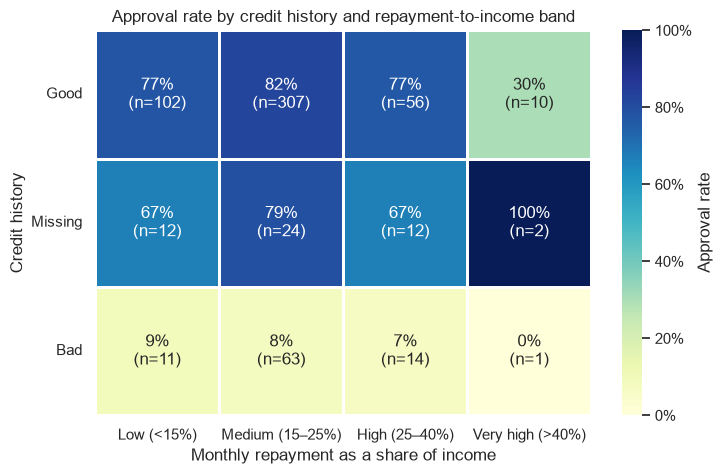

In [8]:
order = ["Good", "Missing", "Bad"]

table = pd.pivot_table(
    loans, index="credit_history", columns="affordability",
    values="approved", aggfunc=["mean", "count"], observed=False,
)
rates = table["mean"].loc[order]
counts = table["count"].loc[order]

# Text for each cell: rate + n
cell_text = rates.map(lambda r: "–" if pd.isna(r) else f"{r:.0%}") + "\n(n=" + counts.astype(int).astype(str) + ")"

ax = sns.heatmap(rates, annot=cell_text, fmt="", cmap="YlGnBu", vmin=0, vmax=1,
                 linewidths=1, linecolor="white", cbar_kws={"label": "Approval rate"})
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.title("Approval rate by credit history and repayment-to-income band")
plt.xlabel("Monthly repayment as a share of income")
plt.ylabel("Credit history")
plt.yticks(rotation=0)
plt.show()

**Observation:** Credit history and affordability work together, but credit history comes first.

- With a **bad** history, applicants were almost always rejected (0–9%) whatever their repayment burden: good affordability cannot make up for a bad history.
- With a **good** history, approval stayed at about 80% as long as repayments took up to 40% of income, then fell to 30% above 40% (n=10). Affordability matters even for good-history applicants, but only at the extreme.
- **Missing** history behaves like a good one where groups are large enough (67–79%). Its 100% in the “very high” band is based on only 2 applicants and should not be read as a finding.

Many cells have fewer than 15 applicants, so differences of a few percentage points between cells are not meaningful.

## 4. Headline chart

### Q6. One chart for the main message
Which single chart tells the most important finding, and how can it be simplified for a pitch
or a README?

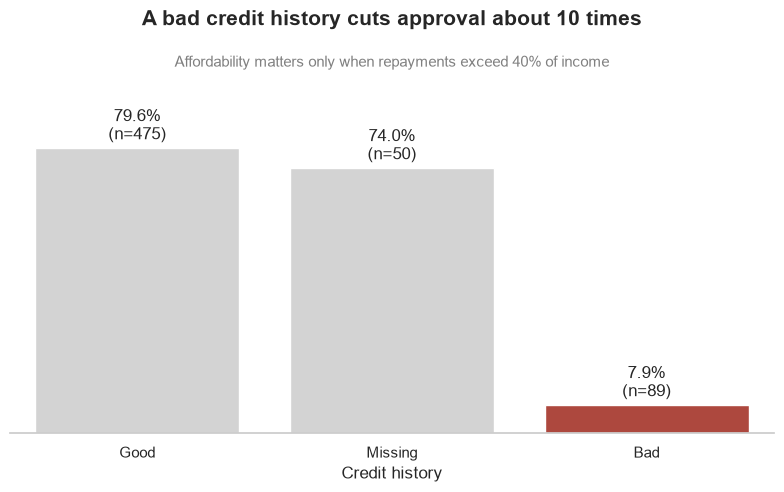

In [9]:
order = ["Good", "Missing", "Bad"]
credit_hist_approval = approval_by(loans, "credit_history").loc[order].reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=credit_hist_approval, x="credit_history", y="approval_rate",
            hue="credit_history", order=order, legend=False, ax=ax,
            palette={"Good": "lightgrey", "Missing": "lightgrey", "Bad": "#c0392b"})

# One container per bar (because of hue), so label each one
labels = [f"{rate:.1%}\n(n={n})" for rate, n in
          zip(credit_hist_approval["approval_rate"], credit_hist_approval["applications"])]
for container, label in zip(ax.containers, labels):
    ax.bar_label(container, labels=[label], padding=3, fontsize=12)

# Remove what the labels already show
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_ylabel("")
ax.set_xlabel("Credit history")
ax.grid(False)
sns.despine(left=True)

fig.suptitle("A bad credit history cuts approval about 10 times", fontsize=15, fontweight="bold")
ax.set_title("Affordability matters only when repayments exceed 40% of income", fontsize=11, color="grey")
plt.tight_layout()
plt.show()

**Observation:** Credit history was chosen for the headline chart because it shows the strongest relationship with approval: 79.6% with a good history vs 7.9% with a bad one. Income alone barely separates approved from rejected applications, and affordability matters only when repayments exceed 40% of income. The chart highlights only the “Bad” bar and removes the axis and grid, so the message is clear at a glance.

## 5. Summary

**Key findings**
- **Income** is strongly right-skewed (median \$5,417), and it barely differs between approved (\$5,439) and rejected (\$5,290) applicants.
- **Credit history** is the strongest signal: 79.6% approval with a good history vs 7.9% with a bad one. A missing history (74.0%) behaves like a good one.
- **Affordability** matters only at the extreme: approval stays at ≈70% up to a 25% repayment-to-income ratio and drops to 38.5% above 40%.
- **Together:** a bad credit history leads to rejection whatever the affordability, while with a good history approval falls only when repayments exceed 40% of income.

**Visualisation lessons**
- A log scale stops a few very large values from dominating the chart and shows the shape of the main group.
- Showing group sizes (n=) makes it clear which rates can be trusted.
- A headline chart states its conclusion in the title and uses colour to highlight a single point.

**Limitations**
- Many combinations in the heatmap have fewer than 15 applicants, so differences of a few percentage points between them are not meaningful.
- The data records one lender's past decisions, not whether loans were actually repaid, so it shows what this lender approved, not who is a good borrower.